# Импорт библиотек

In [1]:
%pip install scikit-learn xgboost openpyxl pandas numpy matplotlib catboost optuna


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, RandomizedSearchCV, learning_curve, KFold, RepeatedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.feature_selection import RFECV, RFE
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from catboost import CatBoostRegressor
import xgboost as xgb
import optuna
import optuna.visualization as vis
from sklearn.model_selection import cross_val_score
from sklearn.base import clone


file_path = r"/Users/artemykagramanian/Desktop/ампермагнит/MCE + ML/обработанные датасеты/magnetocaloric_perovskites_full_descriptors.xlsx"
out_dir = r"DCD_paper"

# Оформление графиков

In [3]:
# Константы для оформления графиков
CM_TO_INCH = 1 / 2.54
COLUMN_WIDTH = 8.5 * CM_TO_INCH

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,

    "axes.linewidth": 0.9,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,

    "figure.dpi": 300,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

COLORS = {
    "blue": "#1f4e79",
    "red": "#b22222",
    "green": "#2e7d32",
    "gray": "#666666",
    "black": "#000000",
}

FEATURE_MAP = {
    'H_ex (T)': r'$H_{\mathrm{ex}}$ (T)',
    'min:mendeleev_number': r'$N_{\mathrm{Mend, min}}$',
    'max:melting_point': r'$T_{\mathrm{m, max}}$',
    'max:density': r'$\rho_{\max}$',
    'max:hhi_r': r'$\mathrm{HHI}_{\mathrm{res, max}}$'
}


def save_figure(fig, name):
    fig.savefig(os.path.join(out_dir, f"{name}.png"), dpi=600)


def save_figure_to(fig, name, folder):
    fig.savefig(os.path.join(folder, f"{name}.png"), dpi=600)


def format_axes(ax, grid=True):
    ax.tick_params(direction="in", top=True, right=True)

    if grid:
        ax.grid(True, linestyle="--", linewidth=0.45, alpha=0.35)

    for spine in ax.spines.values():
        spine.set_linewidth(0.9)

# Функции построения графиков

In [4]:
def plot_delta_s_histogram(delta_s):
    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.hist(
        delta_s,
        bins=22,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        alpha=0.88
    )

    ax.axvline(delta_s.mean(), color=COLORS["red"], linestyle="--",
               linewidth=1.1, label="Mean")
    ax.axvline(delta_s.median(), color=COLORS["black"], linestyle="-",
               linewidth=1.1, label="Median")

    ax.set_xlabel(r"$\Delta S_M$ (J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel("Frequency")
    ax.set_title(r"Distribution of $\Delta S_M$")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
    format_axes(ax)

    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig1_delta_S_histogram")
    plt.show()


def plot_transformation_histogram(y_original):
    y_log = np.log1p(y_original)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.hist(
        y_original,
        bins=22,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        alpha=0.88
    )

    ax.set_xlabel(r"$\Delta S_M$ (J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel("Frequency")
    ax.set_title(r"Original $\Delta S_M$ distribution")

    format_axes(ax)
    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig2_original_distribution")
    plt.show()

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.hist(
        y_log,
        bins=22,
        color=COLORS["green"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        alpha=0.88
    )

    ax.set_xlabel(r"$\log(1+\Delta S_M)$")
    ax.set_ylabel("Frequency")
    ax.set_title(r"Log-transformed distribution")

    format_axes(ax)
    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig3_log_distribution")
    plt.show()


def plot_rfecv_curve(rfecv, optimal_k):
    if rfecv is None:
        print("RFECV plot skipped: RFECV was not performed.")
        return

    mean_scores = rfecv.cv_results_["mean_test_score"]
    n_features = np.arange(1, len(mean_scores) + 1)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.plot(
        n_features,
        mean_scores,
        marker="o",
        markersize=3.2,
        linewidth=1.2,
        color=COLORS["blue"],
        label=r"Mean CV $R^2$"
    )

    ax.axvline(
        optimal_k,
        color=COLORS["red"],
        linestyle="--",
        linewidth=1.1,
        label=f"Optimal: {optimal_k}"
    )

    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(r"Cross-validation $R^2$")
    ax.set_title("RFECV feature selection")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
    format_axes(ax)

    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig4_rfecv_curve")
    plt.show()


def plot_feature_importance(imp_df, top_n=None, exclude=None, model_name="Random Forest",
                             orientation="horizontal"):
    imp = imp_df.copy()

    if exclude:
        imp = imp[~imp["feature"].isin(exclude)]

    imp = imp.sort_values("rf_importance", ascending=True)
    if top_n is not None:
        imp = imp.tail(top_n)

    imp["feature_display"] = imp["feature"].map(lambda x: FEATURE_MAP.get(x, x))
    n_feat = len(imp)

    excl_note = f" (excl. {', '.join(exclude)})" if exclude else ""
    title = f"{model_name}: feature importance" + (
        f" (all {n_feat} features{excl_note})" if top_n is None else ""
    )
    filename_suffix = "_all" if top_n is None else ""
    safe_name = model_name.lower().replace(" ", "_")

    if orientation == "vertical":
        imp_sorted = imp.sort_values("rf_importance", ascending=False)

        fig, ax = plt.subplots(figsize=(max(COLUMN_WIDTH * 2.2, n_feat * 0.28), COLUMN_WIDTH * 1.1))

        ax.bar(
            imp_sorted["feature_display"],
            imp_sorted["rf_importance"],
            color=COLORS["blue"],
            edgecolor=COLORS["black"],
            linewidth=0.45,
            width=0.7
        )

        ax.set_xticks(range(n_feat))
        ax.set_xticklabels(imp_sorted["feature_display"], rotation=90, ha="center", fontsize=6.5)
        ax.set_ylabel("Feature importance")
        ax.set_xlabel("Descriptor")

    else:
        fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 1.35))

        bars = ax.barh(
            imp["feature_display"],
            imp["rf_importance"],
            color=COLORS["blue"],
            edgecolor=COLORS["black"],
            linewidth=0.45,
            height=0.68
        )

        xmax = imp["rf_importance"].max()
        ax.set_xlim(0, xmax * 1.28)

        for bar, value in zip(bars, imp["rf_importance"]):
            ax.text(
                value + xmax * 0.025,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.3f}",
                va="center", ha="left", fontsize=7.5
            )

        ax.set_xlabel("Feature importance")
        ax.set_ylabel("Descriptor")

    ax.set_title(title)
    format_axes(ax)
    fig.tight_layout(pad=0.4 if orientation == "horizontal" else 0.35)
    save_figure(fig, f"Fig5_feature_importance_{safe_name}{filename_suffix}")
    plt.show()


def plot_model_comparison(results_df):
    res = results_df.sort_values("R2_transformed", ascending=True)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.85))

    bars = ax.barh(
        res["Model"],
        res["R2_transformed"],
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68
    )

    xmax = max(res["R2_transformed"].max(), 0.1)
    ax.set_xlim(0, xmax * 1.25)

    for bar, value in zip(bars, res["R2_transformed"]):
        ax.text(
            value + xmax * 0.025,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.set_xlabel(r"$R^2$")
    ax.set_ylabel("Model")
    ax.set_title("Model performance")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig6_model_comparison")
    plt.show()


def plot_parity(y_true, y_pred, name="rf"):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    margin = 0.07 * (max_val - min_val)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH))

    ax.scatter(
        y_true,
        y_pred,
        s=22,
        color=COLORS["green"],
        edgecolor=COLORS["black"],
        linewidth=0.35,
        alpha=0.78
    )

    ax.plot(
        [min_val - margin, max_val + margin],
        [min_val - margin, max_val + margin],
        linestyle="--",
        linewidth=1.1,
        color=COLORS["red"],
        label="Ideal"
    )

    ax.text(
        0.06,
        0.94,
        rf"$R^2$ = {r2:.3f}" + "\n" +
        rf"MAE = {mae:.2f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8.5,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="black",
            linewidth=0.6,
            alpha=0.92
        )
    )

    ax.set_xlabel(r"Experimental $\Delta S_M$" + "\n" + r"(J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel(r"Predicted $\Delta S_M$" + "\n" + r"(J kg$^{-1}$ K$^{-1}$)")
    ax.set_title(r"Experimental vs predicted $\Delta S_M$")

    ax.set_xlim(min_val - margin, max_val + margin)
    ax.set_ylim(min_val - margin, max_val + margin)
    ax.set_aspect("equal", adjustable="box")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0, loc="lower right")
    format_axes(ax)

    fig.tight_layout(pad=0.35)
    save_figure(fig, f"Fig7_parity_plot_{name}")
    plt.show()


def plot_residuals(y_true, y_pred, name="rf"):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    residuals = y_pred - y_true

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.axhline(0, color=COLORS["black"], linewidth=0.9)

    ax.scatter(
        y_true,
        residuals,
        s=22,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.35,
        alpha=0.78
    )

    ax.set_xlabel(r"Experimental $\Delta S_M$" + "\n" + r"(J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel("Residual")
    ax.set_title("Residual analysis")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, f"Fig8_residuals_{name}")
    plt.show()


def plot_learning_curve(train_sizes_abs, train_mean, test_mean, train_std, test_std):
    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.plot(
        train_sizes_abs,
        train_mean,
        marker="o",
        markersize=3.2,
        linewidth=1.2,
        color=COLORS["blue"],
        label="Training"
    )

    ax.plot(
        train_sizes_abs,
        test_mean,
        marker="s",
        markersize=3.2,
        linewidth=1.2,
        color=COLORS["red"],
        label="CV"
    )

    ax.fill_between(
        train_sizes_abs,
        train_mean - train_std,
        train_mean + train_std,
        color=COLORS["blue"],
        alpha=0.15,
        linewidth=0
    )

    ax.fill_between(
        train_sizes_abs,
        test_mean - test_std,
        test_mean + test_std,
        color=COLORS["red"],
        alpha=0.15,
        linewidth=0
    )

    ax.set_xlabel("Training set size")
    ax.set_ylabel(r"$R^2$")
    ax.set_title("Learning curve")

    ax.set_ylim(0.0, 1.05)
    ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
    format_axes(ax)

    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig9_learning_curve_rf")
    plt.show()


def compute_permutation_importance(model, X_test, y_test, feature_names,
                                    n_repeats=50, random_state=42):
    perm = permutation_importance(
        model, X_test, y_test,
        n_repeats=n_repeats,
        random_state=random_state,
        scoring="r2",
        n_jobs=-1
    )
    perm_df = pd.DataFrame({
        "feature": feature_names,
        "perm_importance_mean": perm.importances_mean,
        "perm_importance_std": perm.importances_std
    }).sort_values("perm_importance_mean", ascending=False)
    return perm_df


def plot_permutation_importance(perm_df, top_n=12):
    imp = perm_df.sort_values("perm_importance_mean", ascending=True).tail(top_n)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 1.35))

    bars = ax.barh(
        imp["feature"],
        imp["perm_importance_mean"],
        xerr=imp["perm_importance_std"],
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68,
        capsize=2.5,
        error_kw={"linewidth": 0.8, "ecolor": COLORS["gray"]}
    )

    xmax = (imp["perm_importance_mean"] + imp["perm_importance_std"]).max()
    xmin = min(0, (imp["perm_importance_mean"] - imp["perm_importance_std"]).min())
    ax.set_xlim(xmin * 1.1 if xmin < 0 else 0, xmax * 1.3)

    for bar, value in zip(bars, imp["perm_importance_mean"]):
        ax.text(
            value + xmax * 0.03,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.axvline(0, color=COLORS["black"], linewidth=0.7)
    ax.set_xlabel(r"Permutation importance ($\Delta R^2$, test set)")
    ax.set_ylabel("Descriptor")
    ax.set_title("Random Forest permutation importance")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig5_feature_importance_rf_permutation")
    plt.show()


def select_one_se_features(rfecv, min_features_to_select=1):
    cv_results = rfecv.cv_results_
    mean_scores = np.asarray(cv_results["mean_test_score"])
    std_scores = np.asarray(cv_results["std_test_score"])
    n_features = np.arange(min_features_to_select,
                            min_features_to_select + len(mean_scores))

    n_splits = rfecv.cv if isinstance(rfecv.cv, int) else 5
    se_scores = std_scores / np.sqrt(n_splits)

    best_idx = int(np.argmax(mean_scores))
    best_score = mean_scores[best_idx]
    best_se = se_scores[best_idx]
    threshold = best_score - best_se

    candidates = np.where(mean_scores >= threshold)[0]
    one_se_idx = int(candidates.min())

    return {
        "n_features": n_features,
        "mean_scores": mean_scores,
        "se_scores": se_scores,
        "best_idx": best_idx,
        "best_n": n_features[best_idx],
        "one_se_idx": one_se_idx,
        "one_se_n": n_features[one_se_idx],
        "threshold": threshold,
    }


def plot_rfecv_curve_one_se(rfecv, min_features_to_select=1):
    if rfecv is None:
        print("RFECV plot skipped: RFECV was not performed.")
        return None

    stats = select_one_se_features(rfecv, min_features_to_select)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.plot(
        stats["n_features"],
        stats["mean_scores"],
        marker="o",
        markersize=2.6,
        linewidth=1.0,
        color=COLORS["blue"],
        label=r"Mean CV $R^2$"
    )

    ax.fill_between(
        stats["n_features"],
        stats["mean_scores"] - stats["se_scores"],
        stats["mean_scores"] + stats["se_scores"],
        color=COLORS["blue"],
        alpha=0.15,
        linewidth=0
    )

    ax.axhline(
        stats["threshold"],
        color=COLORS["gray"],
        linestyle=":",
        linewidth=1.0,
        label="Best score - 1 SE"
    )

    ax.axvline(
        stats["best_n"],
        color=COLORS["green"],
        linestyle="--",
        linewidth=1.0,
        label=f"Max score: {stats['best_n']}"
    )

    ax.axvline(
        stats["one_se_n"],
        color=COLORS["red"],
        linestyle="--",
        linewidth=1.2,
        label=f"1-SE optimal: {stats['one_se_n']}"
    )

    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(r"Cross-validation $R^2$")
    ax.set_title("RFECV feature selection (1-SE rule)")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0, fontsize=7)
    format_axes(ax)

    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig4_rfecv_curve_one_se")
    plt.show()

    print(f"Best mean CV R^2 = {stats['mean_scores'][stats['best_idx']]:.4f} "
          f"at {stats['best_n']} features")
    print(f"1-SE rule selects {stats['one_se_n']} features "
          f"(threshold = {stats['threshold']:.4f})")

    return stats


def compute_all_models_importance(models, X_test, y_test, feature_names,
                                   n_repeats=50, random_state=42):
    importance_matrix = pd.DataFrame(index=feature_names)

    for name, model in models.items():
        perm = permutation_importance(
            model, X_test, y_test,
            n_repeats=n_repeats,
            random_state=random_state,
            scoring="r2",
            n_jobs=-1
        )
        importance_matrix[name] = perm.importances_mean

    return importance_matrix


def compute_all_models_native_importance(models, feature_names):
    native_matrix = pd.DataFrame(index=feature_names)

    for name, model in models.items():
        if hasattr(model, "feature_importances_"):
            native_matrix[name] = model.feature_importances_
        elif hasattr(model, "coef_"):
            native_matrix[name] = np.abs(np.ravel(model.coef_))
        elif hasattr(model, "estimators_"):
            sub_importances = [
                est.feature_importances_ for est in model.estimators_
                if hasattr(est, "feature_importances_")
            ]
            if sub_importances:
                native_matrix[name] = np.mean(sub_importances, axis=0)
            else:
                print(f"Skipping '{name}': no native importance available.")
        else:
            print(f"Skipping '{name}': no native importance available.")

    return native_matrix


def plot_single_model_importance(importance_series, model_name, method_label,
                                  save_dir, top_n=12, xlabel=None):
    imp = importance_series.sort_values(ascending=True).tail(top_n)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 1.1))

    bars = ax.barh(
        imp.index,
        imp.values,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68
    )

    xmax = imp.values.max()
    xmin = min(0, imp.values.min())
    ax.set_xlim(xmin * 1.1 if xmin < 0 else 0, xmax * 1.3)

    for bar, value in zip(bars, imp.values):
        ax.text(
            value + xmax * 0.03,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.axvline(0, color=COLORS["black"], linewidth=0.7)
    ax.set_xlabel(xlabel or method_label)
    ax.set_ylabel("Descriptor")
    ax.set_title(f"{model_name}: {method_label}")

    format_axes(ax)
    fig.tight_layout(pad=0.35)

    safe_model = model_name.lower().replace(" ", "_")
    safe_method = method_label.lower().replace(" ", "_")
    save_figure_to(fig, f"{safe_method}_{safe_model}", save_dir)
    plt.show()


def remove_outliers_2_5_sigma(y_true, y_pred, formulas=None, out_dir="."):
    # Принудительно выравниваем массивы в 1D векторы
    y_true = np.ravel(y_true)
    y_pred = np.ravel(y_pred)
    
    # Остатки
    residuals = y_pred - y_true

    # Стандартное отклонение (с ddof=0, как по умолчанию в numpy.std)
    std = residuals.std()
    threshold = 2.5 * std
    
    is_outlier = np.abs(residuals) > threshold
    clean_mask = ~is_outlier  # Маска "чистых" данных

    r2_before = r2_score(y_true, y_pred)
    mae_before = mean_absolute_error(y_true, y_pred)
    r2_after = r2_score(y_true[clean_mask], y_pred[clean_mask])
    mae_after = mean_absolute_error(y_true[clean_mask], y_pred[clean_mask])

    print(f"\n--- Outlier removal (|error| > 2.5 sigma), Random Forest ---")
    print(f"Residual std = {std:.4f}, threshold = {threshold:.4f}")
    print(f"Removed {is_outlier.sum()} of {len(y_true)} points "
          f"({100 * is_outlier.sum() / len(y_true):.1f}%)")
    print(f"R2  before: {r2_before:.3f}  ->  after: {r2_after:.3f}")
    print(f"MAE before: {mae_before:.3f}  ->  after: {mae_after:.3f}")

    # Корректная фильтрация формул
    if formulas is not None:
        formulas_arr = np.ravel(formulas)
        outlier_formulas = formulas_arr[is_outlier]
    else:
        outlier_formulas = np.where(is_outlier)[0]

    outliers_df = pd.DataFrame({
        "formula": outlier_formulas,
        "y_true": y_true[is_outlier],
        "y_pred": y_pred[is_outlier],
        "residual": residuals[is_outlier]
    }).sort_values("residual", key=np.abs, ascending=False)

    # Сохраняем в Excel
    out_path = os.path.join(out_dir, "outliers_removed_2_5_sigma_random_forest.xlsx")
    outliers_df.to_excel(out_path, index=False)
    print(f"Excluded points saved to {out_path}")

    # Возвращаем словарь со ВСЕМИ возможными именами ключей для маски
    return {
        "clean_mask": clean_mask,
        "keep_mask": clean_mask,
        "is_outlier": is_outlier,
        "r2_before": r2_before,
        "r2_after": r2_after,
        "mae_before": mae_before,
        "mae_after": mae_after,
        "outliers_df": outliers_df
    }

def build_model_from_trial(model_name, trial):
    if model_name == "Ridge":
        alpha = trial.suggest_float("alpha", 1e-3, 1e3, log=True)
        return Ridge(alpha=alpha)

    if model_name == "Lasso":
        alpha = trial.suggest_float("alpha", 1e-6, 1.0, log=True)
        return Lasso(alpha=alpha, max_iter=10000)

    if model_name == "ElasticNet":
        alpha = trial.suggest_float("alpha", 1e-5, 1.0, log=True)
        l1_ratio = trial.suggest_float("l1_ratio", 0.005, 1.0)
        return ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=10000)

    if model_name == "Random Forest":
        n_estimators = trial.suggest_int("n_estimators", 10, 500)
        max_depth_choice = trial.suggest_categorical(
            "max_depth", [2, 3, 5, 7, 9, 10, 12, 15, 20, None]
        )
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10)
        return RandomForestRegressor(
            n_estimators=n_estimators, max_depth=max_depth_choice,
            min_samples_leaf=min_samples_leaf, random_state=42, n_jobs=-1
        )

    if model_name == "XGBoost":
        n_estimators = trial.suggest_int("n_estimators", 30, 500)
        max_depth = trial.suggest_int("max_depth", 2, 8)
        learning_rate = trial.suggest_float("learning_rate", 1e-3, 0.15, log=True)
        return xgb.XGBRegressor(
            n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate,
            random_state=42, n_jobs=-1, verbosity=0, objective="reg:squarederror"
        )

    if model_name == "CatBoost":
        iterations = trial.suggest_int("iterations", 50, 700)
        depth = trial.suggest_int("depth", 3, 9)
        learning_rate = trial.suggest_float("learning_rate", 5e-3, 0.2, log=True)
        return CatBoostRegressor(
            iterations=iterations, depth=depth, learning_rate=learning_rate,
            random_state=42, verbose=False
        )

    raise ValueError(model_name)


def run_optuna_search(model_name, X_model, y_target, cv_obj, n_trials):
    def objective(trial):
        model = build_model_from_trial(model_name, trial)
        score = cross_val_score(model, X_model, y_target, cv=cv_obj, scoring="r2", n_jobs=-1)
        return score.mean()

    sampler = optuna.samplers.TPESampler(seed=42)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    best_model = build_model_from_trial(model_name, optuna.trial.FixedTrial(study.best_params))
    return best_model, study.best_params, study.best_value, study

def get_importance(model, feature_names):
    if hasattr(model, "feature_importances_"):
        return pd.Series(model.feature_importances_, index=feature_names)
    elif hasattr(model, "coef_"):
        return pd.Series(np.abs(np.ravel(model.coef_)), index=feature_names)
    else:
        return None

# Обработка данных и признаков

In [5]:
os.makedirs(out_dir, exist_ok=True)
feature_importance_dir = os.path.join(out_dir, "feature_importance_by_model")
os.makedirs(feature_importance_dir, exist_ok=True)

# Загрузка Excel файла
df = pd.read_excel(file_path)
df.columns = df.columns.str.strip()

print(f"Initial dataset size: {df.shape}")
print("Columns:", list(df.columns))

target = "delta_S_M (J/kg K)"

if target not in df.columns:
    raise KeyError(f"Target column '{target}' not found.")

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

if "H_ex (T)" in df.columns:
    df["H_ex (T)"] = pd.to_numeric(df["H_ex (T)"], errors="coerce")

print(f"After target cleaning: {len(df)} rows")

import re

A_SITE_ELEMENTS = {"La","Ce","Pr","Nd","Sm","Eu","Gd","Tb","Dy","Ho","Er","Bi",
                    "Ca","Sr","Ba","Na","K","Pb","Y","Ag"}
B_SITE_ELEMENTS = {"Mn","Fe","Co","Ni","Cu","Ti","Cr","Zr","Sn","Al","Ga","Sc","V","Mo","W","Ru"}

A_RADII = {  # Shannon, CN=12 (Å)
    "La": 1.36, "Ce": 1.34, "Pr": 1.29, "Nd": 1.27, "Sm": 1.24, "Eu": 1.23,
    "Gd": 1.22, "Tb": 1.20, "Dy": 1.19, "Ho": 1.18, "Er": 1.17,
    "Bi": 1.31, "Ca": 1.34, "Sr": 1.44, "Ba": 1.61,
    "Na": 1.39, "K": 1.64, "Pb": 1.49, "Y": 1.16, "Ag": 1.28,
}
A_CHARGE = {"La":3,"Ce":3,"Pr":3,"Nd":3,"Sm":3,"Eu":3,"Gd":3,"Tb":3,"Dy":3,"Ho":3,"Er":3,
            "Bi":3,"Ca":2,"Sr":2,"Ba":2,"Na":1,"K":1,"Pb":2,"Y":3,"Ag":1}

B_RADII_3 = {"Mn": 0.645, "Fe": 0.645, "Co": 0.61, "Ni": 0.60, "Cu": 0.68,
             "Ti": 0.67, "Cr": 0.615, "Al": 0.535, "Ga": 0.62, "Sc": 0.745, "V": 0.64}
B_RADII_4 = {"Mn": 0.53, "Ti": 0.605, "Zr": 0.72, "Sn": 0.69, "Mo": 0.65, "W": 0.66, "Ru": 0.62}

R_O = 1.40  # O2- при CN=6, стандартное приближение


def parse_formula(formula):
    tokens = re.findall(r"([A-Z][a-z]?)(\d*\.?\d*)", str(formula))
    comp = {}
    for el, frac in tokens:
        if not el:
            continue
        frac = float(frac) if frac not in ("", None) else 1.0
        comp[el] = comp.get(el, 0.0) + frac
    return comp


def compute_perovskite_descriptors(formula):
    comp = parse_formula(formula)
    empty = pd.Series({"tolerance_factor": np.nan, "A_site_radius_var": np.nan,
                        "A_site_radius_mean": np.nan, "Mn_avg_oxidation_state": np.nan})
    if not comp or "O" not in comp:
        return empty

    a_comp = {el: f for el, f in comp.items() if el in A_SITE_ELEMENTS}
    b_comp = {el: f for el, f in comp.items() if el in B_SITE_ELEMENTS}
    if not a_comp or not b_comp:
        return empty

    a_total = sum(a_comp.values())
    a_frac = {el: f / a_total for el, f in a_comp.items()}

    a_radii, a_weights = [], []
    for el, w in a_frac.items():
        if el in A_RADII:
            a_radii.append(A_RADII[el])
            a_weights.append(w)

    if not a_radii or abs(sum(a_weights) - 1.0) > 0.15:
        return empty

    a_radii = np.array(a_radii)
    a_weights = np.array(a_weights) / np.sum(a_weights)
    r_a_mean = np.sum(a_weights * a_radii)
    r_a_var = np.sum(a_weights * (a_radii - r_a_mean) ** 2)

    a_charge_total = sum(a_frac[el] * A_CHARGE.get(el, 3) for el in a_frac)
    b_total = sum(b_comp.values())
    b_frac = {el: f / b_total for el, f in b_comp.items()}

    mn_avg_ox = np.nan
    if "Mn" in b_frac and len(b_frac) == 1:
        mn_avg_ox = 6 - a_charge_total

    b_radii, b_weights = [], []
    for el, w in b_frac.items():
        if el == "Mn" and not np.isnan(mn_avg_ox):
            frac4 = np.clip(mn_avg_ox - 3, 0, 1)
            r_mn = B_RADII_3["Mn"] * (1 - frac4) + B_RADII_4["Mn"] * frac4
            b_radii.append(r_mn); b_weights.append(w)
        elif el in B_RADII_3:
            b_radii.append(B_RADII_3[el]); b_weights.append(w)
        elif el in B_RADII_4:
            b_radii.append(B_RADII_4[el]); b_weights.append(w)

    if not b_radii:
        return pd.Series({"tolerance_factor": np.nan, "A_site_radius_var": r_a_var,
                           "A_site_radius_mean": r_a_mean, "Mn_avg_oxidation_state": mn_avg_ox})

    b_radii = np.array(b_radii)
    b_weights = np.array(b_weights) / np.sum(b_weights)
    r_b_mean = np.sum(b_weights * b_radii)

    tolerance_factor = (r_a_mean + R_O) / (np.sqrt(2) * (r_b_mean + R_O))

    return pd.Series({"tolerance_factor": tolerance_factor, "A_site_radius_var": r_a_var,
                       "A_site_radius_mean": r_a_mean, "Mn_avg_oxidation_state": mn_avg_ox})


perovskite_features = df["Clean_formula"].apply(compute_perovskite_descriptors)
df = pd.concat([df, perovskite_features], axis=1)

print("\nНовые структурные признаки — покрытие:")
print(perovskite_features.notna().sum())
print(f"\nПример:\n{df[['Clean_formula'] + list(perovskite_features.columns)].head(10)}")

drop_cols = [
    "Chem formula",
    "Clean_formula",
    "Ref.",
    "T_c (K)",
    "delta_T_ad (K)",
    "RCP(S) (J/kg)",
    target
]

X = df.drop(columns=drop_cols, errors="ignore")
X = X.select_dtypes(include=[np.number])
X = X.fillna(X.median())

y_original = df[target].values
delta_s = pd.Series(y_original)
delta_s = delta_s[delta_s > 0]

print(f"Initial number of features: {X.shape[1]}")

if X.shape[1] == 0:
    raise ValueError("No numeric features found.")

# Фильтрация сильно коррелированных признаков (R > 0.95)
if X.shape[1] > 1:
    corr_matrix = X.corr().abs()
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    to_drop = [
        column for column in upper.columns
        if any(upper[column] > 0.95)
    ]

    X = X.drop(columns=to_drop)

print(f"Number of features after correlation filtering: {X.shape[1]}")

Initial dataset size: (177, 508)
Columns: ['Chem formula', 'T_c (K)', 'delta_T_ad (K)', 'delta_S_M (J/kg K)', 'RCP(S) (J/kg)', 'H_ex (T)', 'Ref.', 'Clean_formula', 'H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'Ar', 'K', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr', 'Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb', 'Te', 'I', 'Xe', 'Cs', 'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu', 'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Po', 'At', 'Rn', 'Fr', 'Ra', 'Ac', 'Th', 'Pa', 'U', 'Np', 'Pu', 'ave:atomic_number', 'ave:atomic_radius', 'ave:atomic_radius_rahm', 'ave:atomic_volume', 'ave:atomic_weight', 'ave:boiling_point', 'ave:bulk_modulus', 'ave:c6_gb', 'ave:covalent_radius_cordero', 'ave:covalent_radius_pyykko', 'ave:covalent_radius_pyykko_double', 'ave:covalent_radius_pyy

# Преобразование целевой переменной, масштабирование и деление выборки

In [6]:
skewness = pd.Series(y_original).skew()

if abs(skewness) > 1:
    print(f"Target distribution is skewed (skew = {skewness:.2f}). Applying log1p transformation.")
    y = np.log1p(y_original)
    target_transformed = True
else:
    print(f"Target distribution is not strongly skewed (skew = {skewness:.2f}).")
    y = y_original.copy()
    target_transformed = False

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

Target distribution is skewed (skew = 2.38). Applying log1p transformation.


# Отбор признаков через RFECV и обучение моделей

In [7]:
optuna.logging.set_verbosity(optuna.logging.WARNING)  # чтобы не спамило по 100 строк на trial

model_matrix_dir = os.path.join(out_dir, "model_matrix")
os.makedirs(model_matrix_dir, exist_ok=True)

rfecv_base_estimators = {
    "Ridge": Ridge(alpha=1.0),

    "Lasso": Lasso(alpha=0.01, max_iter=10000),

    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000),

    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=3, random_state=42, n_jobs=-1),

    "XGBoost": xgb.XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42, verbosity=0, objective="reg:squarederror"),
    
    "CatBoost": CatBoostRegressor(iterations=300, depth=4, learning_rate=0.05, random_state=42, verbose=False)
}

N_TRIALS = {
    "Ridge": 40, "Lasso": 40, "ElasticNet": 60,
    "Random Forest": 300, "XGBoost": 300, 
    "CatBoost": 300,
}


drop_cols = [
    "Chem formula", "Clean_formula", "Ref.", "T_c (K)",
    "delta_T_ad (K)", "RCP(S) (J/kg)", target
]

model_features = {}
dirty_models = {}
dirty_residuals_info = {}
optuna_studies_dirty = {} 

for model_name, base_estimator in rfecv_base_estimators.items():
    print(f"\n\n========== {model_name} ==========")

    # --- Шаг 1: RFECV — находим оптимальное число и имена признаков ---
    print(f"--- {model_name}: RFECV ---")
    rfecv_model = RFECV(
        estimator=clone(base_estimator),
        step=1, cv=cv, scoring="r2",
        min_features_to_select=1,
        n_jobs=-1 if model_name != "CatBoost" else None,
    )
    rfecv_model.fit(X_scaled, y)

    feature_list = list(X.columns[rfecv_model.support_])
    model_features[model_name] = feature_list
    print(f"{model_name}: оптимальное число признаков = {len(feature_list)}")
    #for f in feature_list:
    #    print("  -", f)

    # --- Шаг 2: Optuna на ЭТИХ признаках ---
    print(f"\n--- {model_name}: Optuna, {N_TRIALS[model_name]} trials ---")
    mask = X.columns.isin(feature_list)
    X_model = X_scaled[:, mask]

    dirty_model, dirty_params, dirty_score, dirty_study = run_optuna_search(
        model_name, X_model, y, cv, N_TRIALS[model_name]
    )
    dirty_model.fit(X_model, y)
    optuna_studies_dirty[model_name] = dirty_study

    y_pred_cv = cross_val_predict(clone(dirty_model), X_model, y, cv=cv)
    if target_transformed:
        y_orig_m = np.expm1(y)
        y_pred_cv_orig = np.expm1(y_pred_cv)
    else:
        y_orig_m = y.copy() if isinstance(y, np.ndarray) else y.values.copy()
        y_pred_cv_orig = y_pred_cv.copy()

    r2_dirty_physical = r2_score(y_orig_m, y_pred_cv_orig)
    mae_dirty_physical = mean_absolute_error(y_orig_m, y_pred_cv_orig)

    print(f"{model_name}: best params = {dirty_params}")
    print(f"{model_name}: R2 (transformed CV) = {dirty_score:.4f}, "
          f"R2 (physical) = {r2_dirty_physical:.4f}, MAE = {mae_dirty_physical:.4f}")

    dirty_models[model_name] = dirty_model

    dirty_residuals_info[model_name] = {
    "y_orig_m": y_orig_m,
    "y_pred_cv_orig": y_pred_cv_orig,
    "r2_transformed": dirty_score,
    "mae_transformed": mean_absolute_error(y, y_pred_cv),
}

print("\n\n=== ИТОГ: признаки и метрики по моделям (грязные данные) ===")
for model_name in model_features.keys():
    print(f"{model_name}: {len(model_features[model_name])} признаков")



========== Ridge ==========
--- Ridge: RFECV ---
Ridge: оптимальное число признаков = 24

--- Ridge: Optuna, 40 trials ---


Best trial: 35. Best value: 0.568161: 100%|██████████| 40/40 [00:03<00:00, 11.33it/s]


Ridge: best params = {'alpha': 0.21257068669494475}
Ridge: R2 (transformed CV) = 0.5682, R2 (physical) = 0.4615, MAE = 1.1970


========== Lasso ==========
--- Lasso: RFECV ---
Lasso: оптимальное число признаков = 20

--- Lasso: Optuna, 40 trials ---


Best trial: 12. Best value: 0.518627: 100%|██████████| 40/40 [00:00<00:00, 75.06it/s]


Lasso: best params = {'alpha': 0.003495881914612467}
Lasso: R2 (transformed CV) = 0.5186, R2 (physical) = 0.4701, MAE = 1.2469


========== ElasticNet ==========
--- ElasticNet: RFECV ---
ElasticNet: оптимальное число признаков = 16

--- ElasticNet: Optuna, 60 trials ---


Best trial: 59. Best value: 0.534204: 100%|██████████| 60/60 [00:00<00:00, 72.86it/s]


... (3 outputs left out)

Best trial: 175. Best value: 0.560439: 100%|██████████| 300/300 [01:21<00:00,  3.67it/s]


XGBoost: best params = {'n_estimators': 468, 'max_depth': 4, 'learning_rate': 0.010800684434384356}
XGBoost: R2 (transformed CV) = 0.5604, R2 (physical) = 0.4371, MAE = 1.1449


========== CatBoost ==========
--- CatBoost: RFECV ---
CatBoost: оптимальное число признаков = 63

--- CatBoost: Optuna, 300 trials ---


Best trial: 103. Best value: 0.585991: 100%|██████████| 300/300 [02:33<00:00,  1.95it/s]


CatBoost: best params = {'iterations': 244, 'depth': 3, 'learning_rate': 0.06720106055886681}
CatBoost: R2 (transformed CV) = 0.5860, R2 (physical) = 0.4165, MAE = 1.1894


=== ИТОГ: признаки и метрики по моделям (грязные данные) ===
Ridge: 24 признаков
Lasso: 20 признаков
ElasticNet: 16 признаков
Random Forest: 41 признаков
XGBoost: 44 признаков
CatBoost: 63 признаков


In [8]:
dirty_summary_rows = []
for model_name in model_features.keys():
    info = dirty_residuals_info[model_name]
    dirty_summary_rows.append({
        "Model": model_name,
        "N_features": len(model_features[model_name]),
        "R2_transformed": info["r2_transformed"],
        "MAE_transformed": info["mae_transformed"],
        "R2_physical": r2_score(info["y_orig_m"], info["y_pred_cv_orig"]),
        "MAE_physical": mean_absolute_error(info["y_orig_m"], info["y_pred_cv_orig"]),
    })

dirty_summary_df = pd.DataFrame(dirty_summary_rows).sort_values("R2_physical", ascending=False).reset_index(drop=True)

print("\n=== ТАБЛИЦА (грязные данные) ===")
print(dirty_summary_df.to_string(index=False))


=== ТАБЛИЦА (грязные данные) ===
        Model  N_features  R2_transformed  MAE_transformed  R2_physical  MAE_physical
   ElasticNet          16        0.534204         0.289087     0.481118      1.220843
        Lasso          20        0.518627         0.297472     0.470062      1.246939
        Ridge          24        0.568161         0.272265     0.461544      1.197016
      XGBoost          44        0.560439         0.270567     0.437050      1.144868
     CatBoost          63        0.585991         0.268712     0.416479      1.189406
Random Forest          41        0.554815         0.274805     0.381225      1.185344


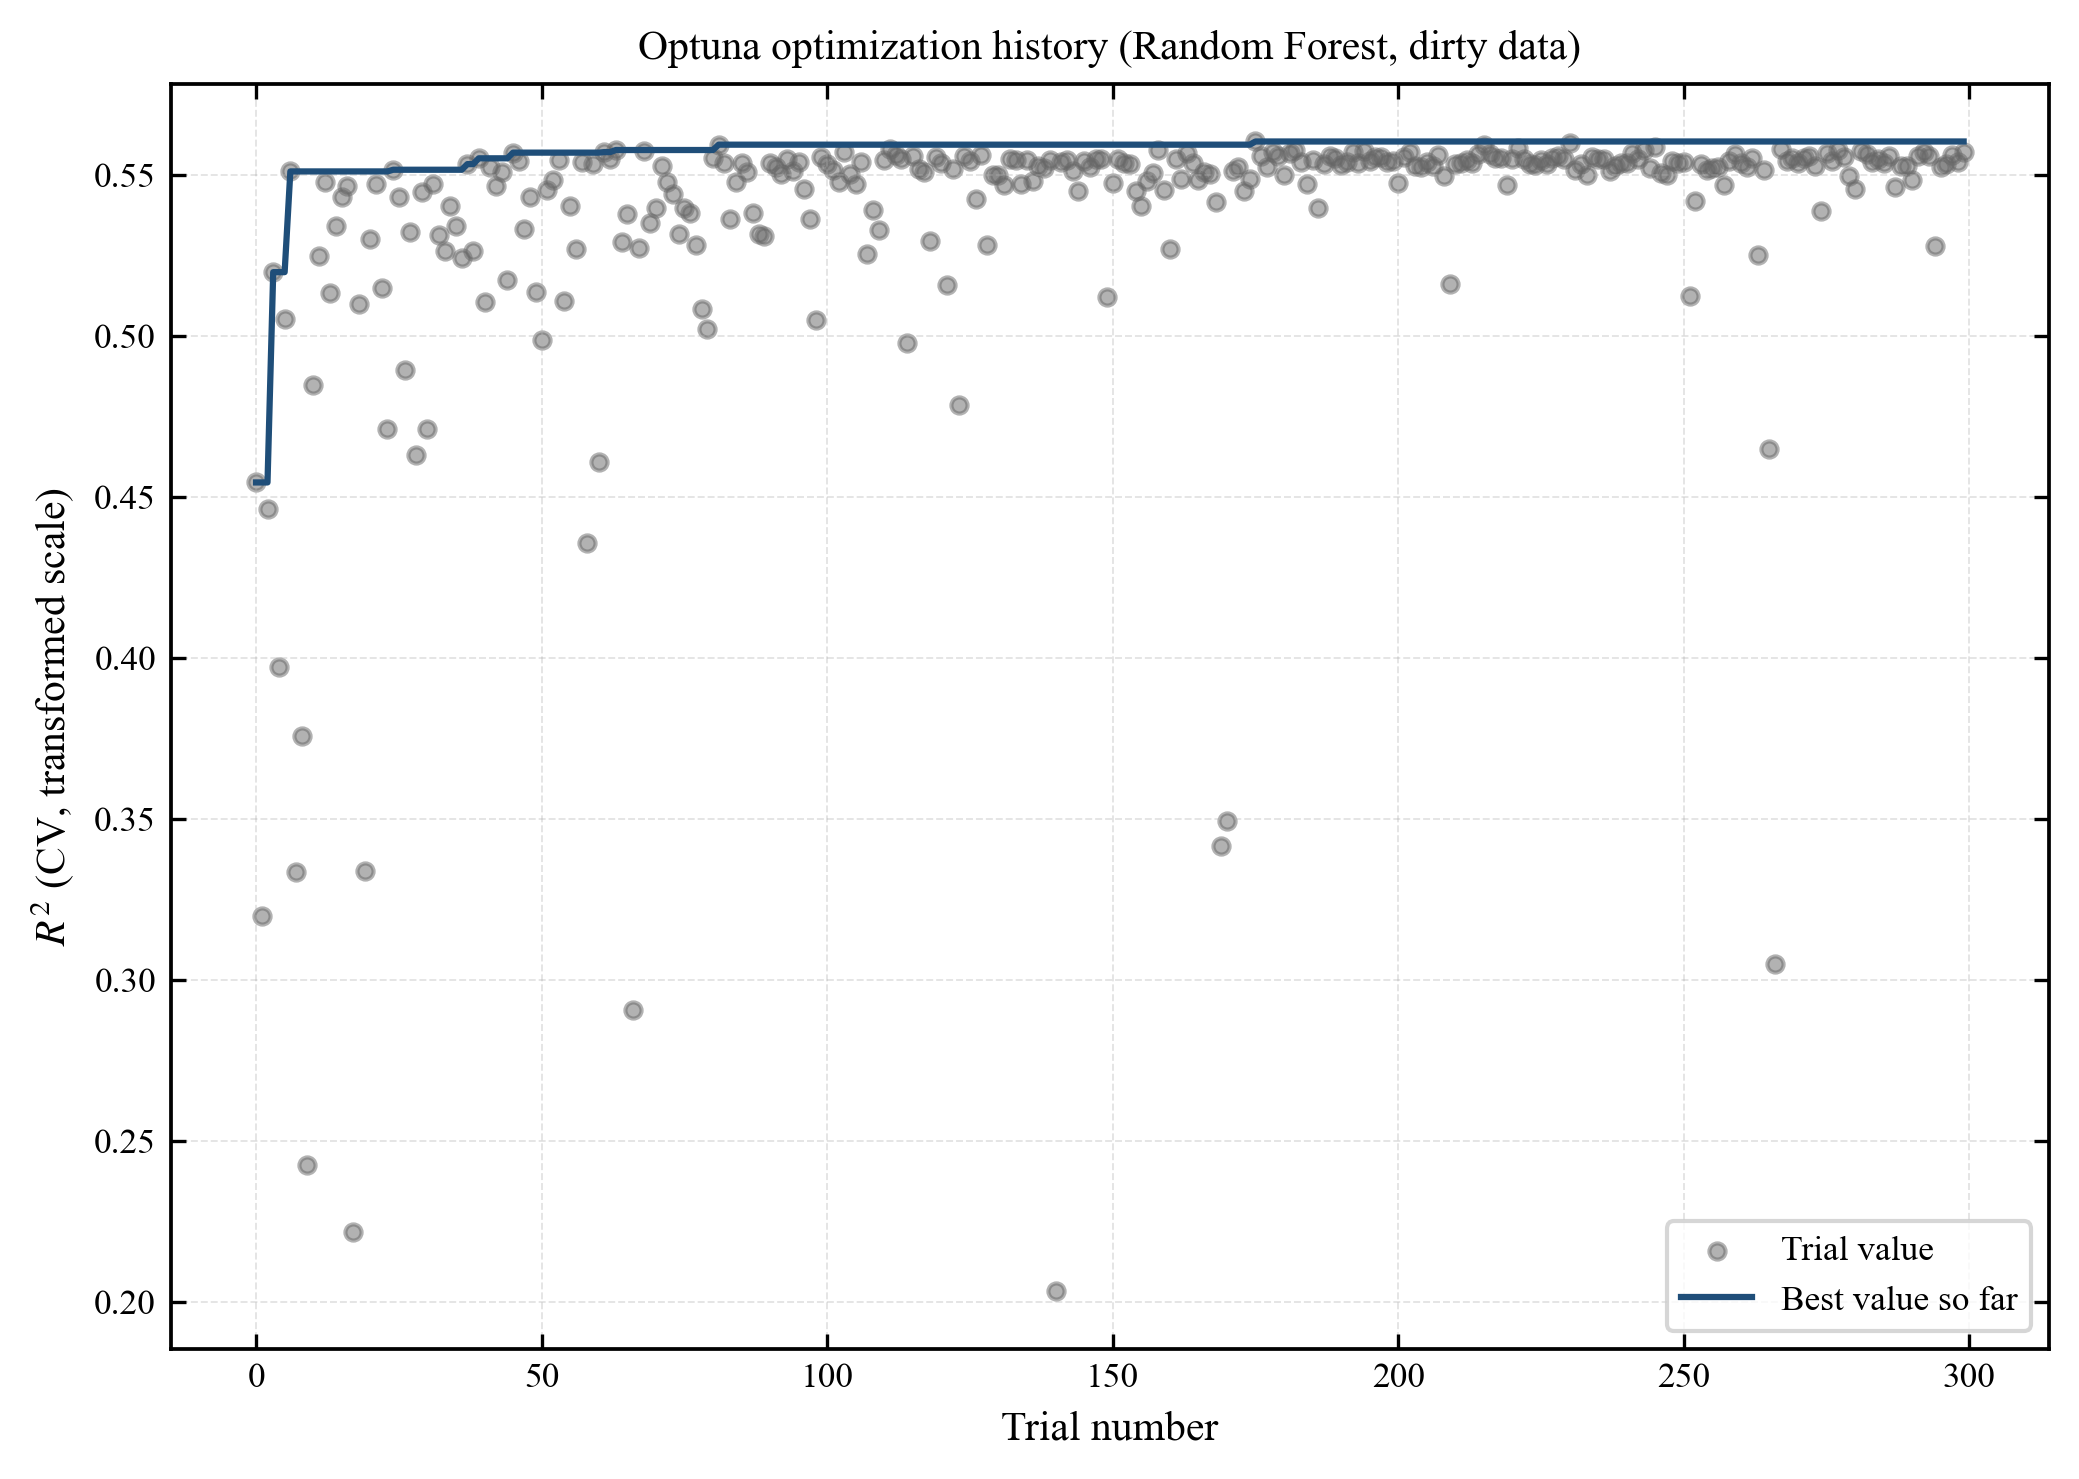

In [9]:
trials_df = optuna_studies_dirty["XGBoost"].trials_dataframe()
best_so_far = trials_df["value"].cummax()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(trials_df["number"], trials_df["value"], s=15, color=COLORS["gray"], alpha=0.5, label="Trial value")
ax.plot(trials_df["number"], best_so_far, color=COLORS["blue"], linewidth=1.5, label="Best value so far")
ax.set_xlabel("Trial number")
ax.set_ylabel(r"$R^2$ (CV, transformed scale)")
ax.set_title("Optuna optimization history (Random Forest, dirty data)")
ax.legend(loc="lower right")
format_axes(ax)
fig.tight_layout()
plt.show()

# Оценка метрик качества и удаление выбросов

In [11]:
clean_data_per_model = {}

for model_name, info in dirty_residuals_info.items():
    print(f"\n========== {model_name}: поиск и удаление выбросов ==========")

    # --- остатки в логарифмической шкале ---
    y_true_log = np.log1p(info["y_orig_m"])
    y_pred_log = np.log1p(info["y_pred_cv_orig"])
    residuals = y_pred_log - y_true_log

    threshold = 2.5 * residuals.std()
    is_outlier = np.abs(residuals) > threshold
    outlier_labels = df.index.values[is_outlier]

    print(f"Residual std (log scale) = {residuals.std():.4f}, threshold = {threshold:.4f}")
    print(f"Выбросов найдено: {is_outlier.sum()} из {len(y)}")

    if is_outlier.sum() > 0:
        outlier_formulas = (df["Clean_formula"].values[is_outlier]
                             if "Clean_formula" in df.columns else outlier_labels)
        print(pd.DataFrame({
            "formula": outlier_formulas,
            "y_true": info["y_orig_m"][is_outlier],
            "residual_log": residuals[is_outlier]
        }).to_string(index=False))

    df_model_clean = df.drop(index=outlier_labels).copy()

    X_model_clean = df_model_clean.drop(columns=drop_cols, errors="ignore")
    X_model_clean = X_model_clean.select_dtypes(include=[np.number])
    X_model_clean = X_model_clean.fillna(X_model_clean.median())

    y_original_model_clean = df_model_clean[target].values
    skew_model_clean = pd.Series(y_original_model_clean).skew()
    target_transformed_model_clean = abs(skew_model_clean) > 1
    y_model_clean = (np.log1p(y_original_model_clean) if target_transformed_model_clean
                      else y_original_model_clean.copy())

    scaler_model_clean = StandardScaler()
    X_scaled_model_clean = scaler_model_clean.fit_transform(X_model_clean)
    cv_clean = KFold(n_splits=5, shuffle=True, random_state=42)

    feature_list = model_features[model_name]
    feature_list_present = [f for f in feature_list if f in X_model_clean.columns]
    missing = set(feature_list) - set(feature_list_present)
    if missing:
        print(f"ВНИМАНИЕ: признаки пропали после чистки: {missing}")

    mask_clean = X_model_clean.columns.isin(feature_list_present)
    X_final = X_scaled_model_clean[:, mask_clean]

    print(f"Dataset size after cleaning: {len(df_model_clean)} rows (was {len(df)}), "
          f"features used: {mask_clean.sum()}")

    clean_data_per_model[model_name] = {
        "df_model_clean": df_model_clean,
        "X_final": X_final,
        "y_model_clean": y_model_clean,
        "cv_clean": cv_clean,
        "feature_list_present": feature_list_present,
        "target_transformed_model_clean": target_transformed_model_clean,
        "n_outliers": int(is_outlier.sum()),
        "n_features_used": int(mask_clean.sum()),
    }


========== Ridge: поиск и удаление выбросов ==========
Residual std (log scale) = 0.3692, threshold = 0.9231
Выбросов найдено: 3 из 175
         formula  y_true  residual_log
  La0.7Ca0.3MnO3     9.4     -1.169179
La0.67Sr0.33MnO3    14.8     -1.771177
 La1.4Ca1.6Mn2O7    16.8     -1.109751
Dataset size after cleaning: 172 rows (was 175), features used: 24

========== Lasso: поиск и удаление выбросов ==========
Residual std (log scale) = 0.3892, threshold = 0.9731
Выбросов найдено: 4 из 175
                   formula  y_true  residual_log
La0.67Ba0.33Mn0.98Ti0.02O3    6.34     -1.059191
            La0.7Ca0.3MnO3    9.40     -1.181126
          La0.67Sr0.33MnO3   14.80     -1.798471
           La1.4Ca1.6Mn2O7   16.80     -1.113129
Dataset size after cleaning: 171 rows (was 175), features used: 20

========== ElasticNet: поиск и удаление выбросов ==========
Residual std (log scale) = 0.3830, threshold = 0.9575
Выбросов найдено: 3 из 175
         formula  y_true  residual_log
  La0.7Ca0

In [12]:
saved_models = {}
saved_data = {}
optuna_results = []
optuna_studies_clean = {}

for model_name, clean_info in clean_data_per_model.items():
    print(f"\n========== {model_name} (Optuna на чистых данных, {N_TRIALS[model_name]} trials) ==========")

    X_final = clean_info["X_final"]
    y_model_clean = clean_info["y_model_clean"]
    cv_clean = clean_info["cv_clean"]

    clean_model, clean_params, clean_score, clean_study = run_optuna_search(
        model_name, X_final, y_model_clean, cv_clean, N_TRIALS[model_name]
    )
    clean_model.fit(X_final, y_model_clean)
    optuna_studies_clean[model_name] = clean_study

    y_pred_final = cross_val_predict(clone(clean_model), X_final, y_model_clean, cv=cv_clean)
    mae_transformed_clean = mean_absolute_error(y_model_clean, y_pred_final)

    if clean_info["target_transformed_model_clean"]:
        y_orig_final = np.expm1(y_model_clean)
        y_pred_final_orig = np.expm1(y_pred_final)
    else:
        y_orig_final = y_model_clean.copy()
        y_pred_final_orig = y_pred_final.copy()

    r2_physical = r2_score(y_orig_final, y_pred_final_orig)
    mae_physical = mean_absolute_error(y_orig_final, y_pred_final_orig)

    print(f"{model_name}: best params (clean) = {clean_params}")
    print(f"{model_name}: R2 (transformed CV) = {clean_score:.4f}, "
          f"R2 (physical) = {r2_physical:.4f}, MAE (physical) = {mae_physical:.4f}")

    saved_models[model_name] = clean_model
    saved_data[model_name] = {
        "X_final": X_final,
        "y_model_clean": y_model_clean,
        "cv_clean_seed": cv_clean,
        "feature_list_present": clean_info["feature_list_present"],
        "target_transformed": clean_info["target_transformed_model_clean"],
        "y_orig_final": y_orig_final,
        "y_pred_final_orig": y_pred_final_orig,
        "r2_physical": r2_physical,
        "mae_physical": mae_physical,
        "r2_transformed": clean_score,
        "mae_transformed": mae_transformed_clean,
        "df_model_clean": clean_info["df_model_clean"],
    }

    optuna_results.append({
        "Model": model_name,
        "N_features": clean_info["n_features_used"],
        "N_outliers_removed": clean_info["n_outliers"],
        "Best_hyperparameters": str(clean_params),
        "R2_CV_transformed": clean_score,
        "MAE_CV_transformed": mae_transformed_clean,
        "R2_CV_physical": r2_physical,
        "MAE_CV_physical": mae_physical,
    })

optuna_results_df = pd.DataFrame(optuna_results).sort_values("R2_CV_physical", ascending=False)
optuna_results_df.to_excel(os.path.join(model_matrix_dir, "optuna_results.xlsx"), index=False)

# --- таблица, как для грязных данных ---
clean_summary_rows = []
for model_name in saved_data.keys():
    data = saved_data[model_name]
    clean_summary_rows.append({
        "Model": model_name,
        "N_features": len(data["feature_list_present"]),
        "N_outliers_removed": clean_data_per_model[model_name]["n_outliers"],
        "R2_transformed": data["r2_transformed"],
        "MAE_transformed": data["mae_transformed"],
        "R2_physical": data["r2_physical"],
        "MAE_physical": data["mae_physical"],
    })

clean_summary_df = pd.DataFrame(clean_summary_rows).sort_values("R2_physical", ascending=False).reset_index(drop=True)

print("\n=== ТАБЛИЦА (очищенные данные) ===")
print(clean_summary_df.to_string(index=False))


========== Ridge (Optuna на чистых данных, 40 trials) ==========


Best trial: 14. Best value: 0.63368: 100%|██████████| 40/40 [00:04<00:00,  8.13it/s] 


Ridge: best params (clean) = {'alpha': 0.6679058515482004}
Ridge: R2 (transformed CV) = 0.6337, R2 (physical) = 0.6192, MAE (physical) = 1.0348

========== Lasso (Optuna на чистых данных, 40 trials) ==========


Best trial: 39. Best value: 0.608628: 100%|██████████| 40/40 [00:00<00:00, 72.34it/s]


Lasso: best params (clean) = {'alpha': 0.0023549453944194717}
Lasso: R2 (transformed CV) = 0.6086, R2 (physical) = 0.6433, MAE (physical) = 1.0498

========== ElasticNet (Optuna на чистых данных, 60 trials) ==========


Best trial: 48. Best value: 0.596544: 100%|██████████| 60/60 [00:00<00:00, 69.11it/s]


... (3 outputs left out)

Best trial: 148. Best value: 0.632174: 100%|██████████| 300/300 [01:00<00:00,  4.95it/s]


XGBoost: best params (clean) = {'n_estimators': 389, 'max_depth': 4, 'learning_rate': 0.09291007176265341}
XGBoost: R2 (transformed CV) = 0.6322, R2 (physical) = 0.6145, MAE (physical) = 0.9968

========== CatBoost (Optuna на чистых данных, 300 trials) ==========


Best trial: 206. Best value: 0.665908: 100%|██████████| 300/300 [14:35<00:00,  2.92s/it]


CatBoost: best params (clean) = {'iterations': 498, 'depth': 6, 'learning_rate': 0.03521689262263843}
CatBoost: R2 (transformed CV) = 0.6659, R2 (physical) = 0.6202, MAE (physical) = 0.9007

=== ТАБЛИЦА (очищенные данные) ===
        Model  N_features  N_outliers_removed  R2_transformed  MAE_transformed  R2_physical  MAE_physical
        Lasso          20                   4        0.608628         0.267906     0.643328      1.049790
Random Forest          41                   6        0.615205         0.243896     0.640893      0.896572
   ElasticNet          16                   3        0.596544         0.274669     0.631637      1.067580
     CatBoost          63                   7        0.665908         0.233537     0.620173      0.900676
        Ridge          24                   3        0.633680         0.257314     0.619247      1.034834
      XGBoost          44                   5        0.632174         0.250273     0.614473      0.996755


# Расчет кривой обучения (Learning Curve)

=== Random Forest: расчёт learning curve ===


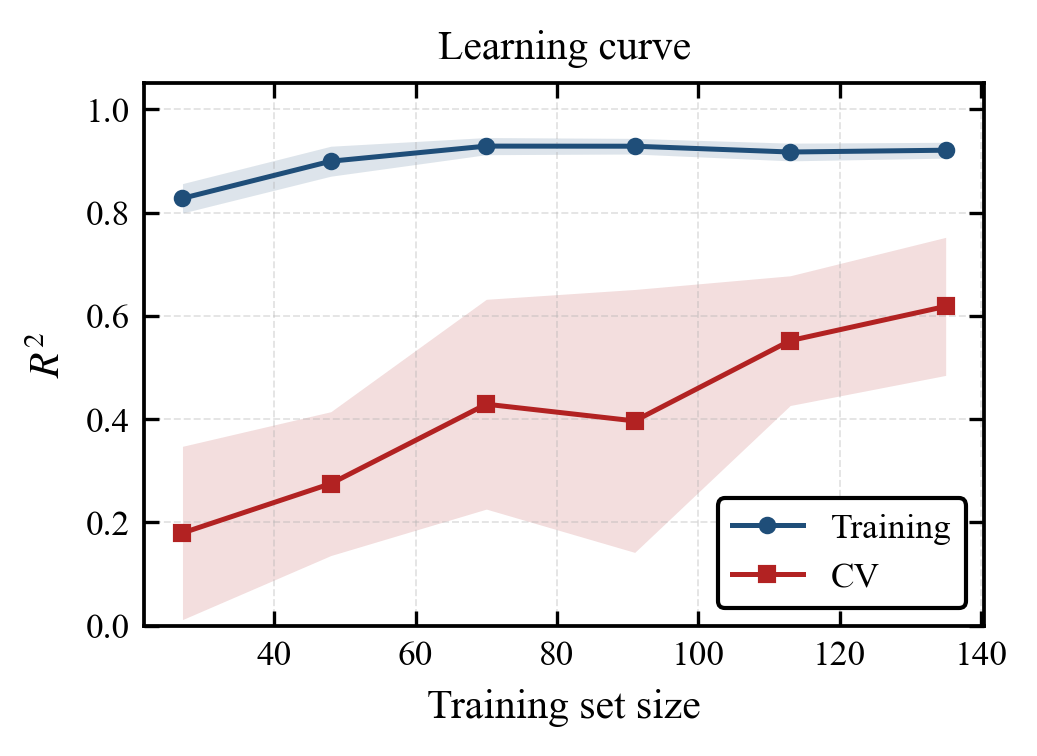

  Train R2: [0.828 0.899 0.929 0.928 0.917 0.921]
  CV R2:    [0.18  0.275 0.429 0.397 0.552 0.618]


In [13]:
model_name = "Random Forest"
model = saved_models[model_name]
data = saved_data[model_name]

print(f"=== {model_name}: расчёт learning curve ===")

train_sizes_abs, train_scores, test_scores = learning_curve(
    clone(model),
    data["X_final"],
    data["y_model_clean"],
    cv=data["cv_clean_seed"],
    scoring="r2",
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
test_mean = test_scores.mean(axis=1)
test_std = test_scores.std(axis=1)

plot_learning_curve(
    train_sizes_abs,
    train_mean,
    test_mean,
    train_std,
    test_std
)

print(f"  Train R2: {np.round(train_mean, 3)}")
print(f"  CV R2:    {np.round(test_mean, 3)}")

=== Lasso: расчёт learning curve ===


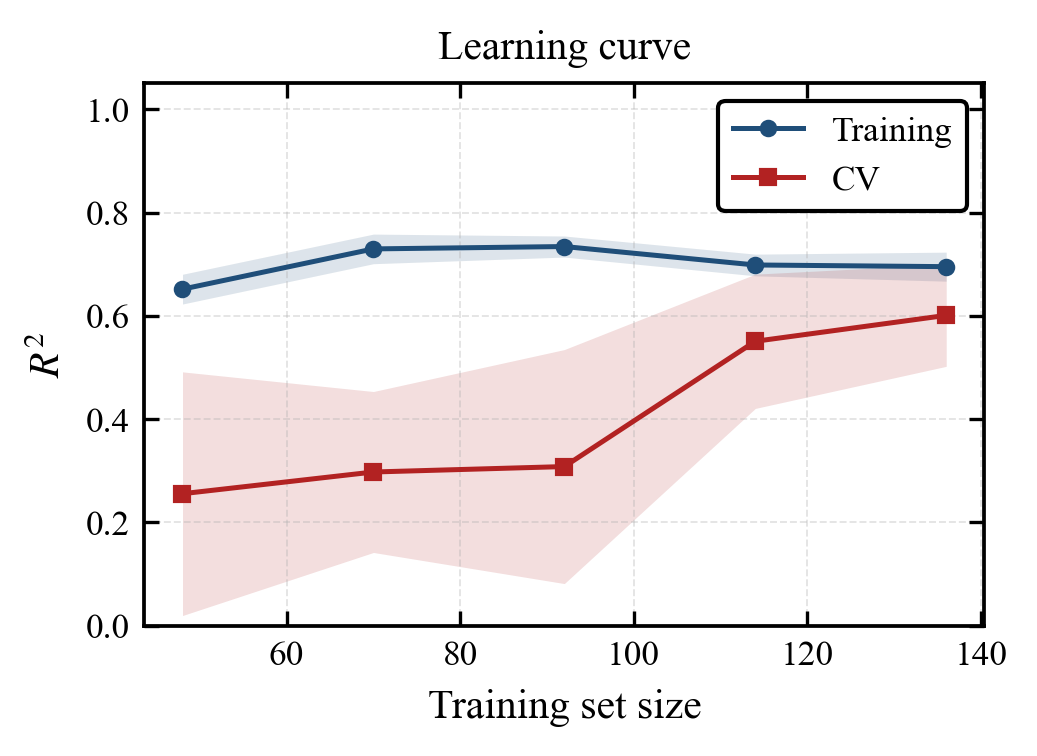

  Train R2: [0.553 0.652 0.73  0.734 0.698 0.695]
  CV R2:    [-1.998  0.256  0.298  0.308  0.551  0.601]


In [14]:
model_name = "Lasso"
model = saved_models[model_name]
data = saved_data[model_name]

print(f"=== {model_name}: расчёт learning curve ===")

train_sizes_abs, train_scores, test_scores = learning_curve(
    clone(model),
    data["X_final"],
    data["y_model_clean"],
    cv=data["cv_clean_seed"],
    scoring="r2",
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
test_mean = test_scores.mean(axis=1)
test_std = test_scores.std(axis=1)

plot_learning_curve(
    train_sizes_abs[1:],
    train_mean[1:],
    test_mean[1:],
    train_std[1:],
    test_std[1:]
)

print(f"  Train R2: {np.round(train_mean, 3)}")
print(f"  CV R2:    {np.round(test_mean, 3)}")

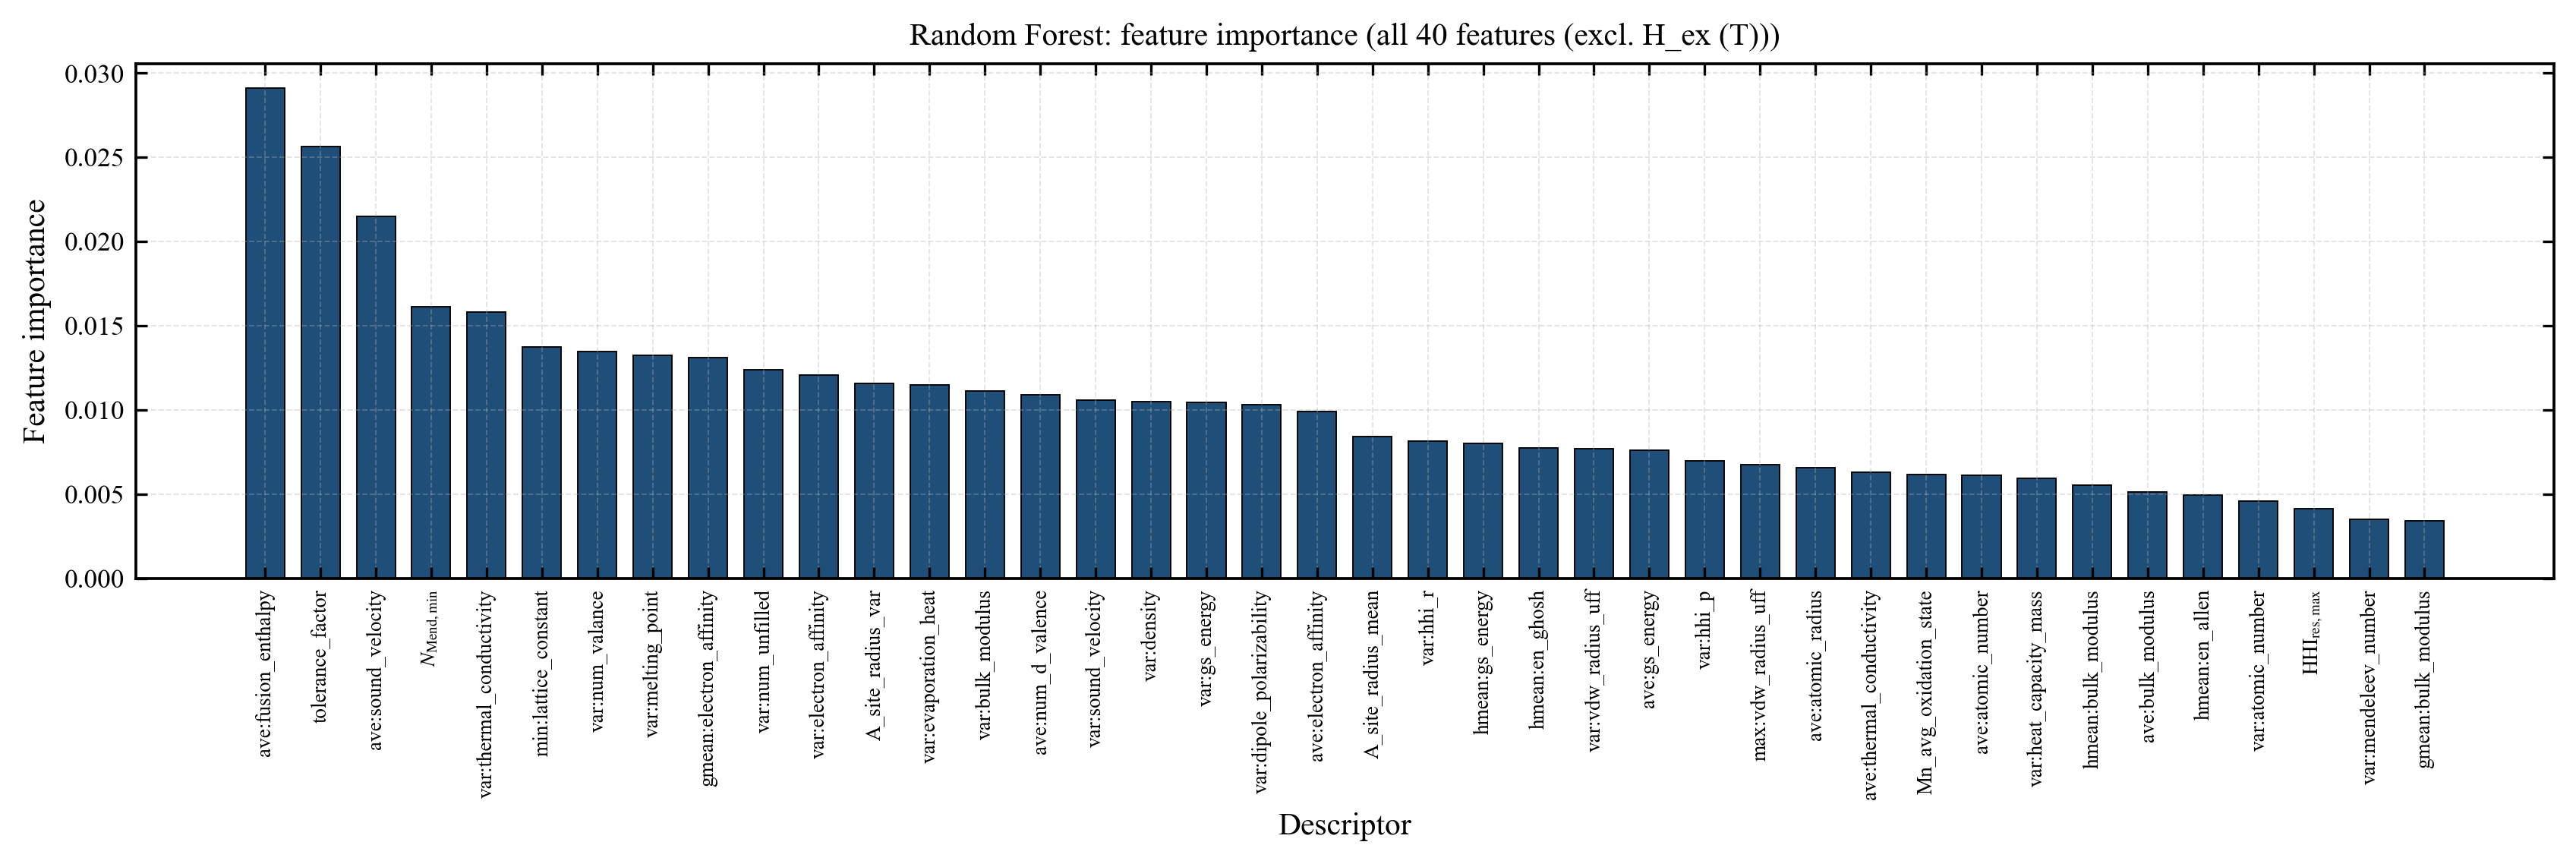

In [15]:
model_name = "Random Forest"
model = saved_models[model_name]
data = saved_data[model_name]

imp_series = get_importance(model, data["feature_list_present"])

if imp_series is not None:
    imp_df = pd.DataFrame({
        "feature": imp_series.index,
        "rf_importance": imp_series.values
    })
    plot_feature_importance(
        imp_df, top_n=None, exclude=["H_ex (T)"],
        model_name=model_name, orientation="vertical"
    )
else:
    print(f"{model_name}: важность признаков недоступна")

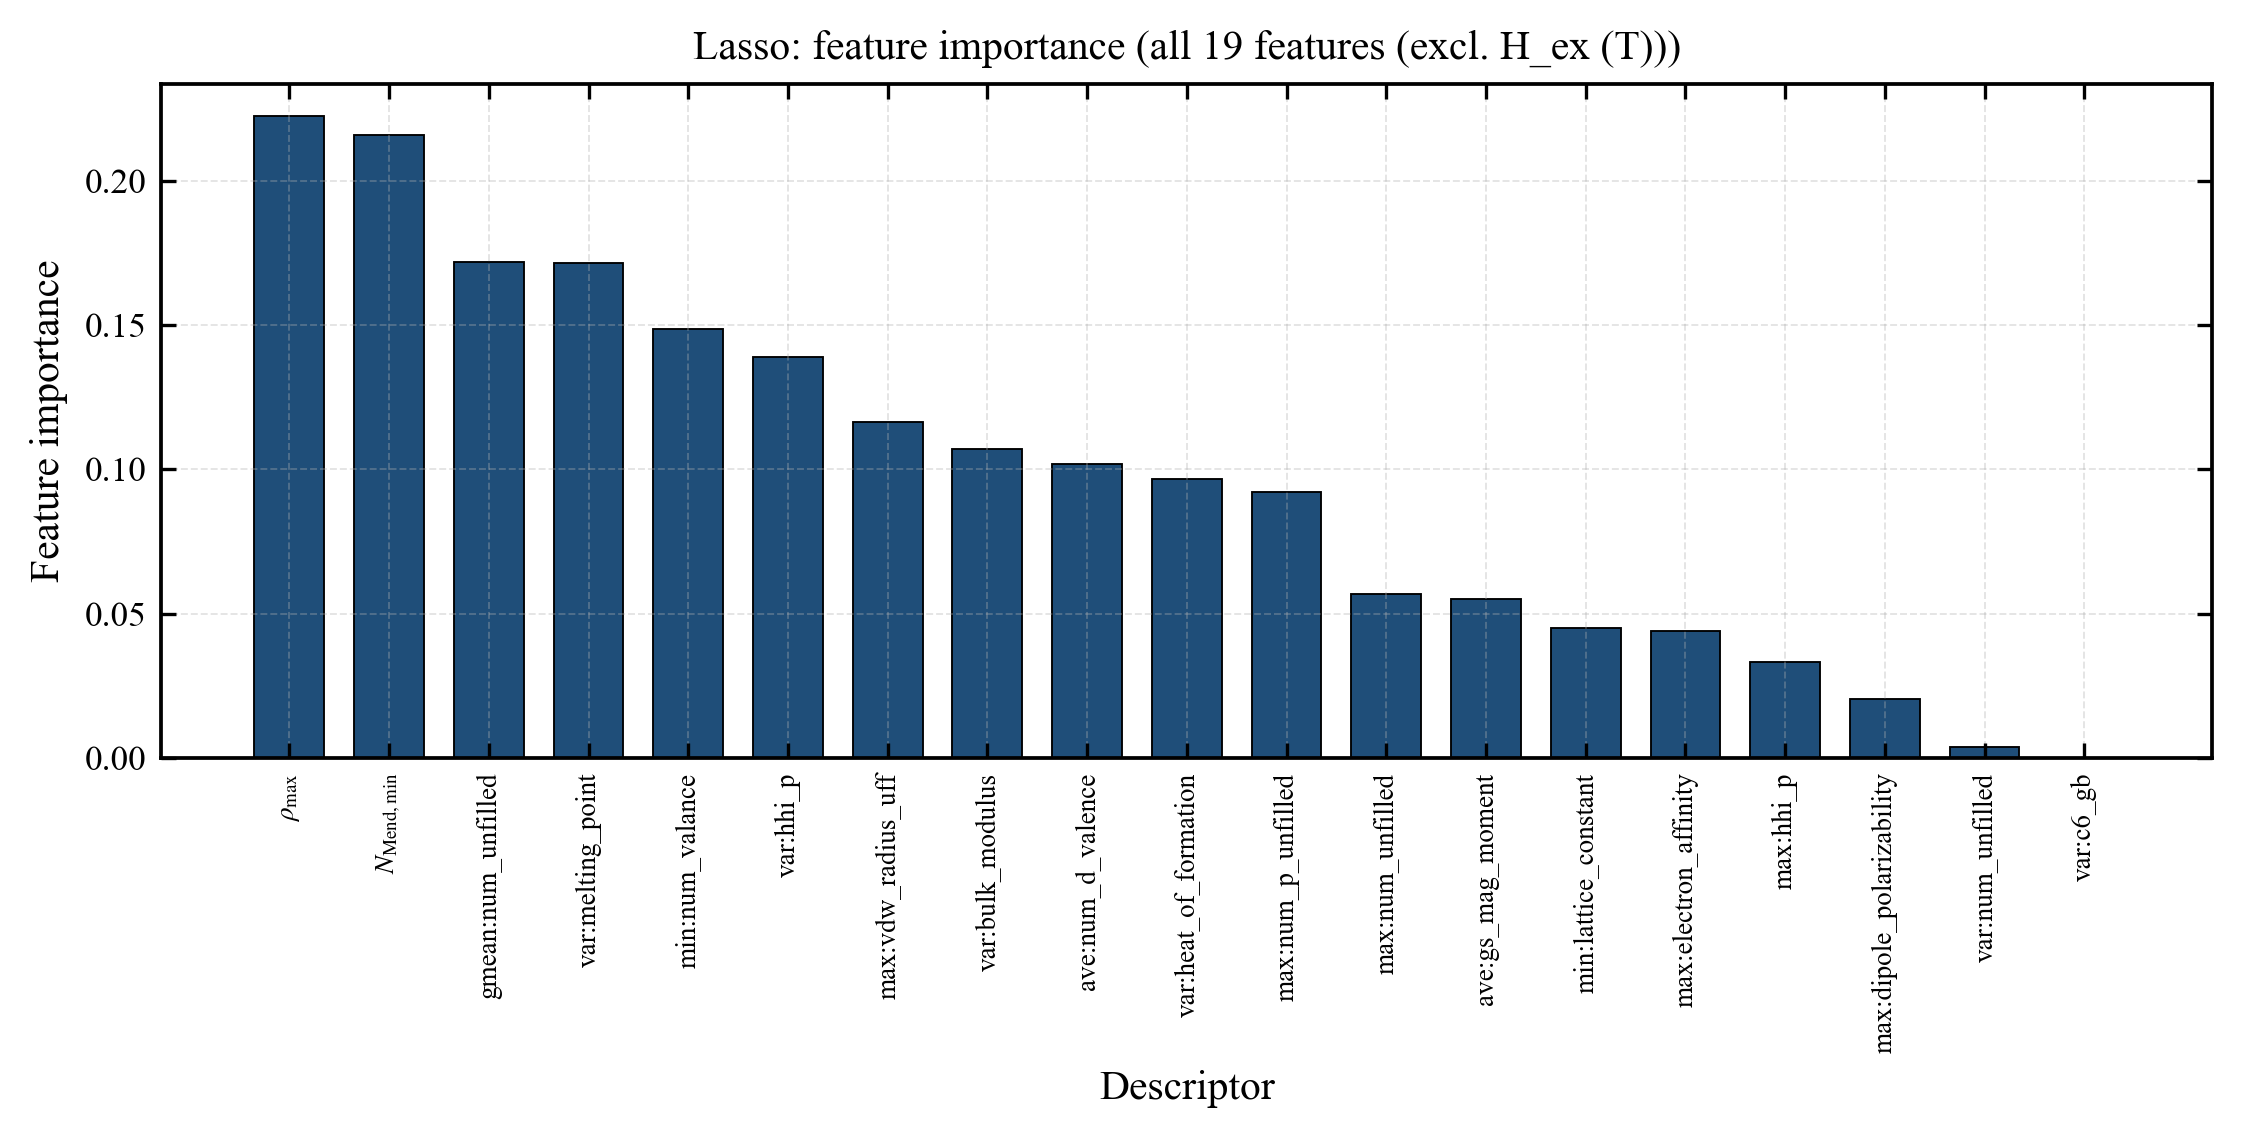

In [17]:
model_name = "Lasso"
model = saved_models[model_name]
data = saved_data[model_name]

imp_series = get_importance(model, data["feature_list_present"])

if imp_series is not None:
    imp_df = pd.DataFrame({
        "feature": imp_series.index,
        "rf_importance": imp_series.values
    })
    plot_feature_importance(
        imp_df, top_n=None, exclude=["H_ex (T)"],
        model_name=model_name, orientation="vertical"
    )
else:
    print(f"{model_name}: важность признаков недоступна")

# Отрисовка всех основных графиков

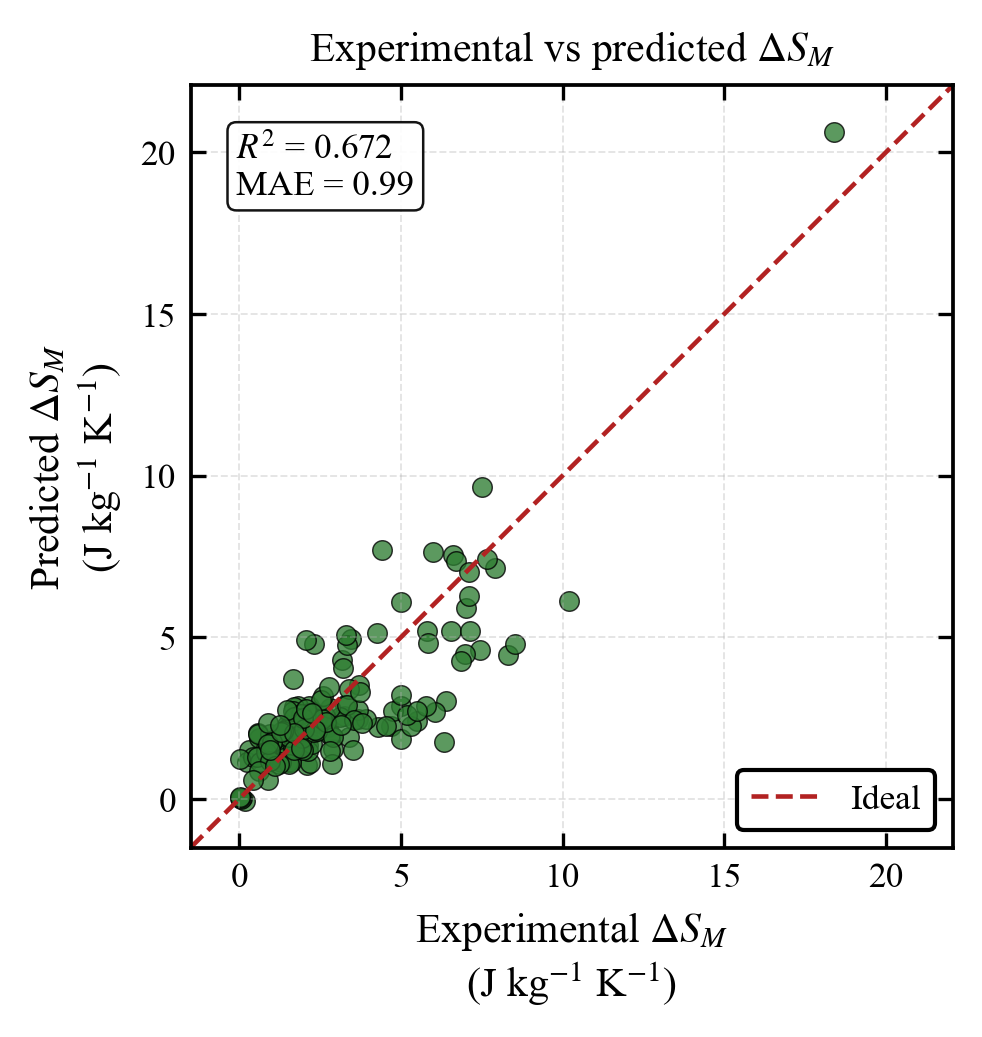

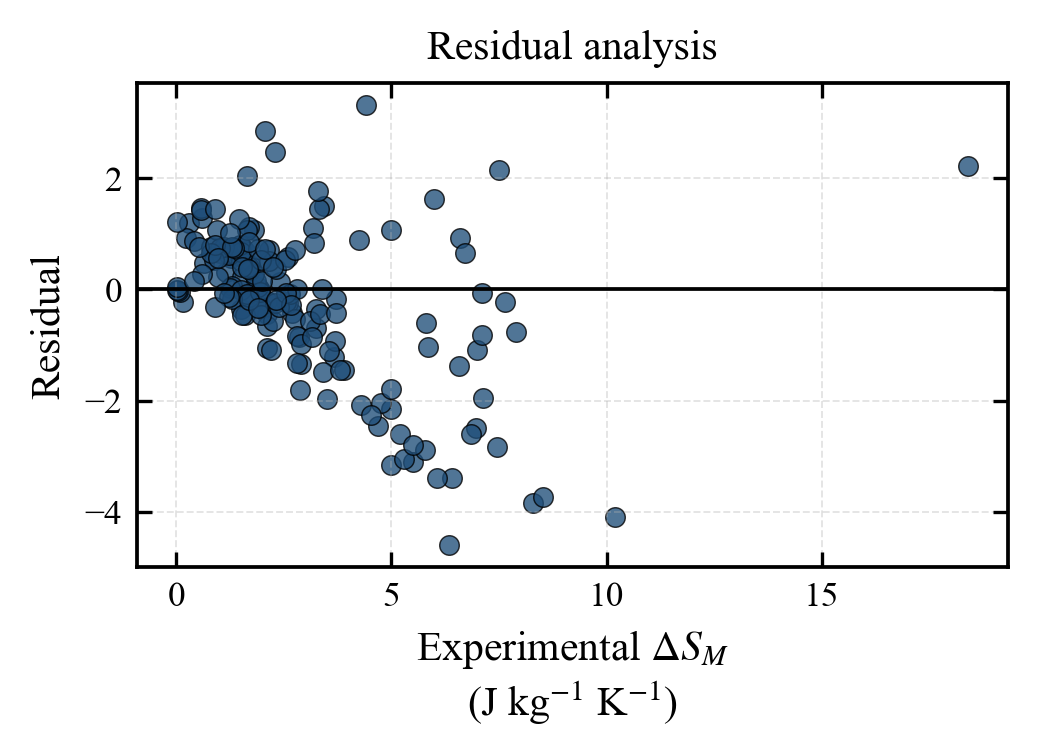

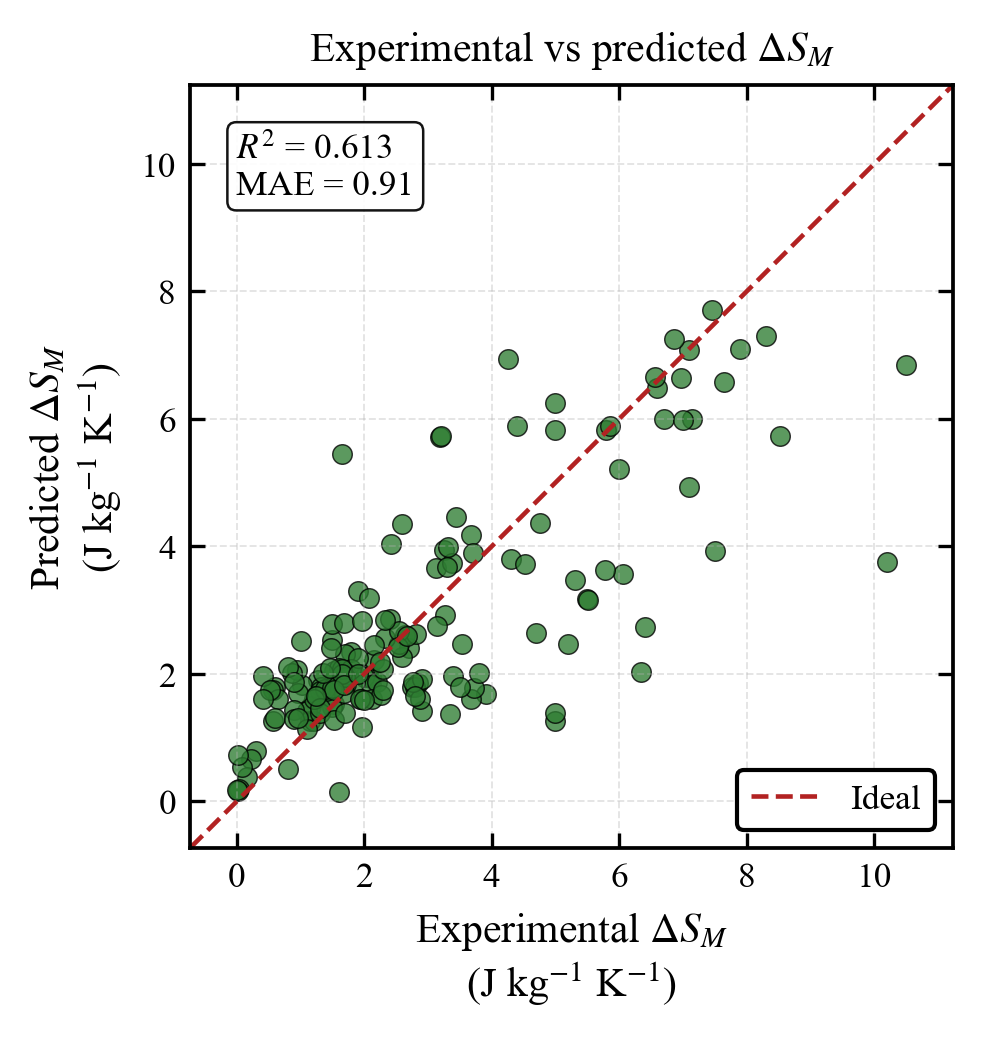

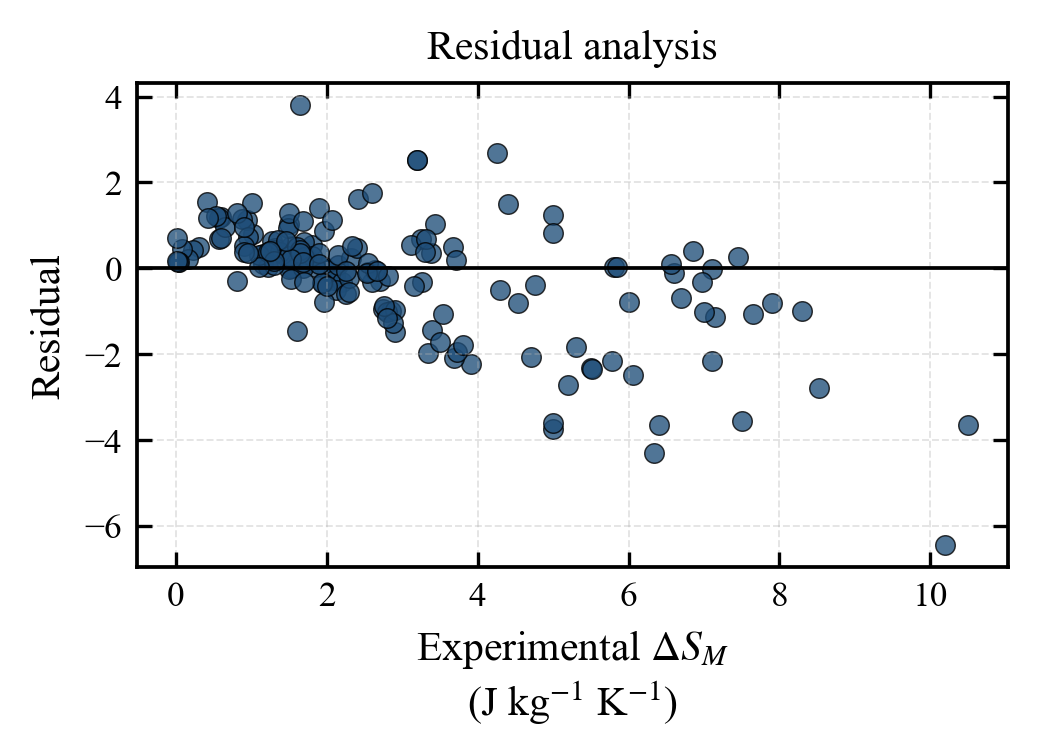

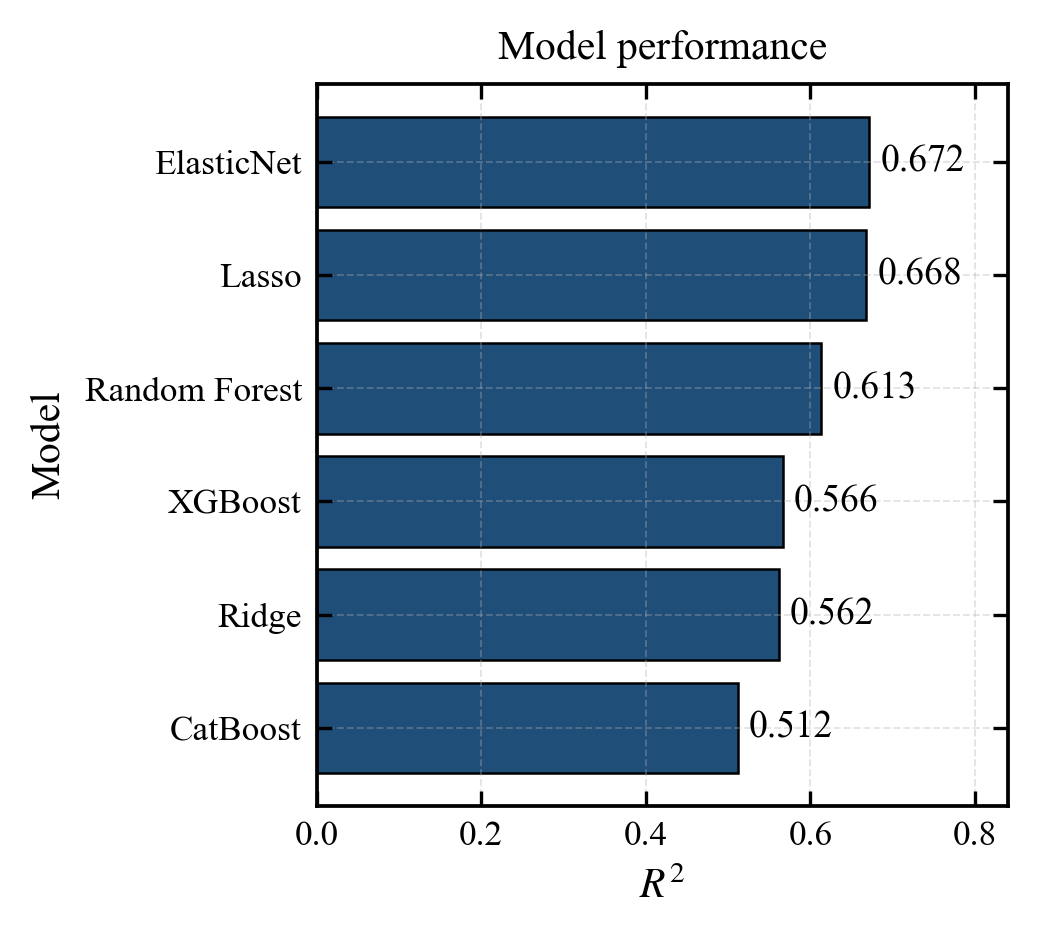

In [ ]:
for model_name in ["ElasticNet", "Random Forest"]:
    data = saved_data[model_name]

    plot_parity(data["y_orig_final"], data["y_pred_final_orig"],
                name=model_name.lower().replace(" ", "_"))
    plot_residuals(data["y_orig_final"], data["y_pred_final_orig"],
                    name=model_name.lower().replace(" ", "_"))

# --- сравнение моделей: bar chart по clean_summary_df ---
summary_sorted = clean_summary_df.set_index("Model").sort_values("R2_physical", ascending=True)

fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.9))

bars = ax.barh(
    summary_sorted.index,
    summary_sorted["R2_physical"],
    color=COLORS["blue"],
    edgecolor=COLORS["black"],
    linewidth=0.6,
)

xmax = summary_sorted["R2_physical"].max()
ax.set_xlim(0, xmax * 1.25)

for bar, val in zip(bars, summary_sorted["R2_physical"]):
    ax.text(
        val + xmax * 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.3f}",
        va="center", ha="left", fontsize=9
    )

ax.set_xlabel(r"$R^2$")
ax.set_ylabel("Model")
ax.set_title("Model performance")

format_axes(ax)
fig.tight_layout(pad=0.35)
save_figure(fig, "Fig_model_comparison_r2")
plt.show()

# Сохранение финальных таблиц Excel

In [ ]:
# Сохранение финальных таблиц Excel
dirty_summary_df.to_excel(os.path.join(out_dir, "model_metrics_dirty.xlsx"), index=False)
clean_summary_df.to_excel(os.path.join(out_dir, "model_metrics_clean.xlsx"), index=False)
optuna_results_df.to_excel(os.path.join(out_dir, "optuna_best_hyperparameters.xlsx"), index=False)

# Сохраняем важность признаков для каждой модели отдельно
with pd.ExcelWriter(os.path.join(out_dir, "feature_importance_all_models.xlsx")) as writer:
    for model_name in saved_models.keys():
        imp_series = get_importance(saved_models[model_name], saved_data[model_name]["feature_list_present"])
        if imp_series is not None:
            imp_df_export = pd.DataFrame({
                "feature": imp_series.index,
                "importance": imp_series.values
            }).sort_values("importance", ascending=False)
            imp_df_export.to_excel(writer, sheet_name=model_name[:31], index=False)

print(f"\nAll figures and tables saved to folder: {out_dir}")


All figures and tables saved to folder: DCD_paper
